# Домашнє завдання до модуля «Підходи до покращення якості»

Мета: на наборі даних Autos порівняти показники взаємної інформації (mutual information) між вхідними ознаками й цільовою змінною із показниками важливості цих ознак у прогнозній моделі (feature importance).

### 1. Імпорт пакетів і завантаження набору даних Autos

In [1]:
import pickle
from pathlib import Path
from urllib.request import urlretrieve

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.feature_selection import mutual_info_regression
from sklearn.ensemble import GradientBoostingRegressor

Набір даних беремо з локальної папки репозиторію курсу. Якщо її немає (наприклад, під час запуску в Google Colab), спочатку завантажуємо файл із репозиторію курсу на GitHub.

In [2]:
DATA_DIR = Path('../datasets')

FILE_NAME = 'mod_05_topic_10_various_data.pkl'

if not (DATA_DIR / FILE_NAME).exists():
    DATA_DIR = Path()
    urlretrieve('https://raw.githubusercontent.com/goitacademy/'
                'MACHINE-LEARNING-NEO/main/datasets/' + FILE_NAME,
                DATA_DIR / FILE_NAME)

In [3]:
with open(DATA_DIR / FILE_NAME, 'rb') as fl:
    datasets = pickle.load(fl)

autos = datasets['autos']
autos.shape

(193, 24)

In [4]:
autos.head()

,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,...,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg,price
0,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9,111,5000,21,27,13495
1,alfa-romero,gas,std,2,convertible,rwd,front,88.6,168.8,64.1,...,130,mpfi,3.47,2.68,9,111,5000,21,27,16500
2,alfa-romero,gas,std,2,hatchback,rwd,front,94.5,171.2,65.5,...,152,mpfi,2.68,3.47,9,154,5000,19,26,16500
3,audi,gas,std,4,sedan,fwd,front,99.8,176.6,66.2,...,109,mpfi,3.19,3.40,10,102,5500,24,30,13950
4,audi,gas,std,4,sedan,4wd,front,99.4,176.6,66.4,...,136,mpfi,3.19,3.40,8,115,5500,18,22,17450


In [5]:
X = autos.copy()
y = X.pop('price')

X.dtypes.value_counts()

int64      9
object     8
float64    6
Name: count, dtype: int64

### 2. Визначення переліку дискретних ознак

До дискретних (у широкому розумінні) відносимо всі категоріальні ознаки, а також числові, значення яких за своєю природою можуть бути тільки цілими: кількість дверей і кількість циліндрів. Перевіримо кількість унікальних значень числових ознак, щоб переконатися у правильності такого рішення.

In [6]:
X.select_dtypes(include=np.number).nunique().sort_values()

num_of_doors           2
num_of_cylinders       6
compression_ratio      8
peak_rpm              21
city_mpg              28
highway_mpg           30
stroke                36
bore                  38
engine_size           40
width                 41
height                46
wheel_base            50
horsepower            56
length                71
curb_weight          165
dtype: int64

Окрім `num_of_doors` (2 значення) і `num_of_cylinders` (6 значень), потенційним кандидатом є `compression_ratio` (8 значень). Проте ступінь стиснення є фізичною неперервною величиною, яка в цьому наборі просто округлена, тому залишаємо її неперервною.

In [7]:
cat_features = X.select_dtypes('object').columns

discrete_features = cat_features.to_list() + ['num_of_doors',
                                              'num_of_cylinders']

discrete_features

['make',
 'fuel_type',
 'aspiration',
 'body_style',
 'drive_wheels',
 'engine_location',
 'engine_type',
 'fuel_system',
 'num_of_doors',
 'num_of_cylinders']

Категоріальні ознаки перетворюємо на числові, надаючи унікальним категоріям довільні числові мітки за допомогою методу `factorize()`.

In [8]:
for colname in cat_features:
    X[colname], _ = X[colname].factorize()

X.head()

,make,fuel_type,aspiration,num_of_doors,body_style,drive_wheels,engine_location,wheel_base,length,width,...,num_of_cylinders,engine_size,fuel_system,bore,stroke,compression_ratio,horsepower,peak_rpm,city_mpg,highway_mpg
0,0,0,0,2,0,0,0,88.6,168.8,64.1,...,4,130,0,3.47,2.68,9,111,5000,21,27
1,0,0,0,2,0,0,0,88.6,168.8,64.1,...,4,130,0,3.47,2.68,9,111,5000,21,27
2,0,0,0,2,1,0,0,94.5,171.2,65.5,...,6,152,0,2.68,3.47,9,154,5000,19,26
3,1,0,0,4,2,1,0,99.8,176.6,66.2,...,4,109,0,3.19,3.40,10,102,5500,24,30
4,1,0,0,4,2,2,0,99.4,176.6,66.4,...,5,136,0,3.19,3.40,8,115,5500,18,22


### 3. Розрахунок показників взаємної інформації

In [9]:
mi_scores = mutual_info_regression(
    X, y,
    discrete_features=X.columns.isin(discrete_features),
    random_state=42)

mi_scores = pd.Series(mi_scores,
                      name='MI Scores',
                      index=X.columns)

mi_scores.sort_values(ascending=False).head(10)

curb_weight    0.911713
engine_size    0.900925
horsepower     0.891165
highway_mpg    0.887362
city_mpg       0.774127
width          0.679991
length         0.612483
wheel_base     0.588635
make           0.543268
bore           0.497420
Name: MI Scores, dtype: float64

### 4. Побудова моделі для оцінки важливості ознак

Категоріальні ознаки вже закодовані числовими мітками, що є прийнятним для моделей на основі дерев рішень: вони не оперують масштабом ознаки, а шукають оптимальні пороги розбиття вибірки.

Будуємо ансамбль `GradientBoostingRegressor` і отримуємо нормалізовані значення важливості ознак з атрибута `.feature_importances_`.

In [10]:
model = GradientBoostingRegressor(random_state=42).fit(X, y)

gb_scores = pd.Series(model.feature_importances_,
                      name='GB Scores',
                      index=X.columns)

gb_scores.sort_values(ascending=False).head(10)

engine_size         0.629277
curb_weight         0.172734
horsepower          0.058336
highway_mpg         0.030180
width               0.016727
make                0.015686
wheel_base          0.013254
length              0.012475
num_of_cylinders    0.010778
city_mpg            0.007257
Name: GB Scores, dtype: float64

### 5. Масштабування показників

Показники взаємної інформації та важливості ознак мають різну природу й різні шкали, тому для коректного порівняння приводимо їх до єдиної шкали за допомогою методу `.rank(pct=True)`, який замінює абсолютні значення на перцентильний ранг.

In [11]:
scores = (pd.concat([mi_scores, gb_scores], axis=1)
          .rank(pct=True)
          .sort_values('MI Scores', ascending=False))

scores.head(10).round(2)

,MI Scores,GB Scores
curb_weight,1.00,0.96
engine_size,0.96,1.00
horsepower,0.91,0.91
highway_mpg,0.87,0.87
city_mpg,0.83,0.61
width,0.78,0.83
length,0.74,0.70
wheel_base,0.70,0.74
make,0.65,0.78
bore,0.61,0.52


### 6. Візуалізація порівняння

Переформатовуємо дані у «довгий» формат за допомогою методу `.melt()` і будуємо згрупований стовпчиковий графік.

In [12]:
sns.set_theme()

melted = scores.reset_index().melt(id_vars='index')

melted.head()

,index,variable,value
0,curb_weight,MI Scores,1.000000
1,engine_size,MI Scores,0.956522
2,horsepower,MI Scores,0.913043
3,highway_mpg,MI Scores,0.869565
4,city_mpg,MI Scores,0.826087


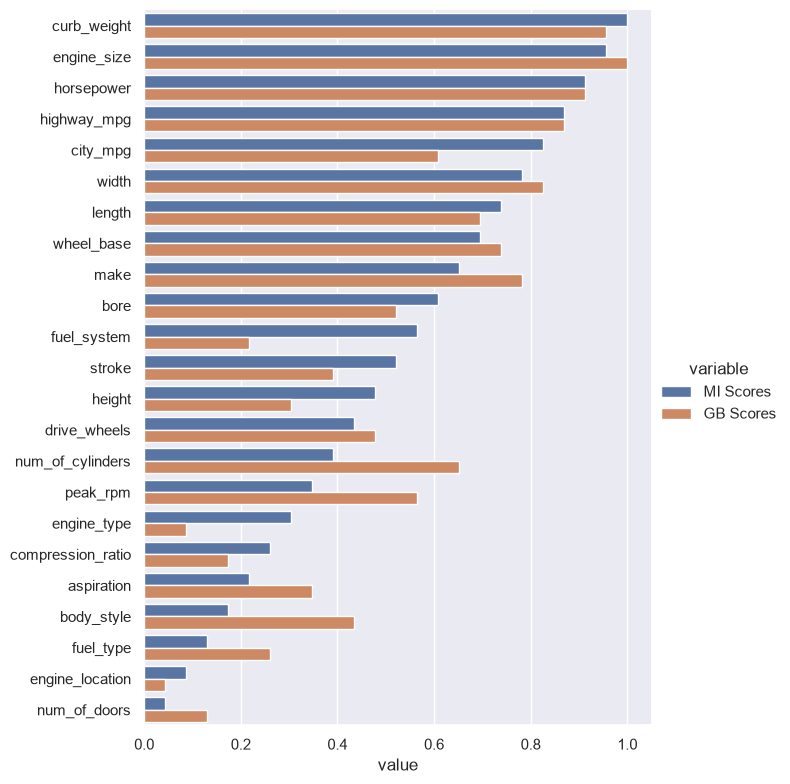

In [13]:
g = sns.catplot(data=melted,
                y='index',
                x='value',
                hue='variable',
                kind='bar',
                height=8,
                aspect=0.9)

g.set(ylabel='')

plt.show()

Додатково подивимось, для яких саме ознак розбіжність між двома оцінками є найбільшою.

In [14]:
(scores
 .assign(diff=lambda x: (x['MI Scores'] - x['GB Scores']).abs())
 .sort_values('diff', ascending=False)
 .head(8)
 .round(2))

,MI Scores,GB Scores,diff
fuel_system,0.57,0.22,0.35
num_of_cylinders,0.39,0.65,0.26
body_style,0.17,0.43,0.26
engine_type,0.30,0.09,0.22
city_mpg,0.83,0.61,0.22
peak_rpm,0.35,0.57,0.22
height,0.48,0.30,0.17
make,0.65,0.78,0.13


### 7. Висновки

1. Обидва підходи узгоджено виділяють групу найважливіших ознак, пов'язаних із розміром і потужністю автомобіля: `curb_weight`, `engine_size`, `horsepower`, `width`, `highway_mpg`. Тобто для найсильніших предикторів «корисність» за показником взаємної інформації та важливість у моделі збігаються.
2. Разом із тим для низки ознак оцінки суттєво розходяться. Найбільші розбіжності отримали `fuel_system` (MI 0.57 проти GB 0.22), `city_mpg` (0.83 проти 0.61), `engine_type` (0.30 проти 0.09) і `height` (0.48 проти 0.30). Ці ознаки самі по собі непогано пов'язані з ціною, але дублюють інформацію, яка вже міститься в «сильніших» ознаках: витрата пального в місті майже повторює `highway_mpg`, а тип паливної системи й тип двигуна — інформацію про об'єм двигуна та потужність. Дерева рішень обирають для розбиття лише одну ознаку з групи взаємозамінних, тому решта залишаються майже незадіяними.
3. Спостерігається й зворотна ситуація: `num_of_cylinders` (MI 0.39 проти GB 0.65), `body_style` (0.17 проти 0.43) і `peak_rpm` (0.35 проти 0.57) мають низький показник взаємної інформації, але виявились помітно кориснішими для моделі. Це саме той випадок, який ми бачили в конспекті на прикладі `fuel_type`: ознака працює у взаємодії з іншими ознаками, а показник MI оцінює зв'язок кожної ознаки з цільовою змінною ізольовано й такої взаємодії не бачить.
4. Отже, «корисність» окремої ознаки з точки зору взаємної інформації може значно відрізнятися від її важливості в моделі для прийняття рішень. Практичний висновок: показник MI зручний як швидкий орієнтир на етапі EDA, але не може бути єдиною підставою для відкидання ознак — рішення про відбір варто перевіряти вже на побудованій моделі.
5. Слід також враховувати, що обидві оцінки мають свої обмеження: MI не бачить взаємодій між ознаками, а важливість ознак у дерев рішень схильна завищувати внесок ознак із великою кількістю унікальних значень.